In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, json, os

df = pd.read_csv('combined_merged.csv')
df.head()

,DATE_TIME,PLANT_ID,AC_POWER,DC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,0.0,0.0,25.184316,22.857507,0.0
1,2020-05-15 00:00:00,4136001,0.0,0.0,27.004764,25.060789,0.0
2,2020-05-15 00:15:00,4135001,0.0,0.0,25.084589,22.761668,0.0
3,2020-05-15 00:15:00,4136001,0.0,0.0,26.880811,24.421869,0.0
4,2020-05-15 00:30:00,4135001,0.0,0.0,24.935753,22.592306,0.0


In [2]:
print(df.shape)
print(df.isna().sum())
print('duplicates:', df.duplicated(['DATE_TIME', 'PLANT_ID']).sum())
df.describe().T

(6417, 7)
DATE_TIME              0
PLANT_ID               0
AC_POWER               0
DC_POWER               0
AMBIENT_TEMPERATURE    1
MODULE_TEMPERATURE     1
IRRADIATION            1
dtype: int64
duplicates: 0


,count,mean,std,min,25%,50%,75%,max
PLANT_ID,6417.0,4.135509e+06,499.977022,4.135001e+06,4.135001e+06,4.136001e+06,4.136001e+06,4.136001e+06
AC_POWER,6417.0,5.844489e+03,7576.456403,0.000000e+00,0.000000e+00,6.399071e+02,1.189813e+04,2.915021e+04
DC_POWER,6417.0,3.633706e+04,69577.597847,0.000000e+00,0.000000e+00,1.264839e+03,1.779019e+04,2.989378e+05
AMBIENT_TEMPERATURE,6416.0,2.683477e+01,3.934008,2.039850e+01,2.367318e+01,2.597393e+01,2.936660e+01,3.918164e+01
MODULE_TEMPERATURE,6416.0,3.198662e+01,11.836145,1.814042e+01,2.246663e+01,2.647802e+01,4.093247e+01,6.663595e+01
IRRADIATION,6416.0,2.314410e-01,0.307142,0.000000e+00,0.000000e+00,2.358190e-02,4.455864e-01,1.221652e+00


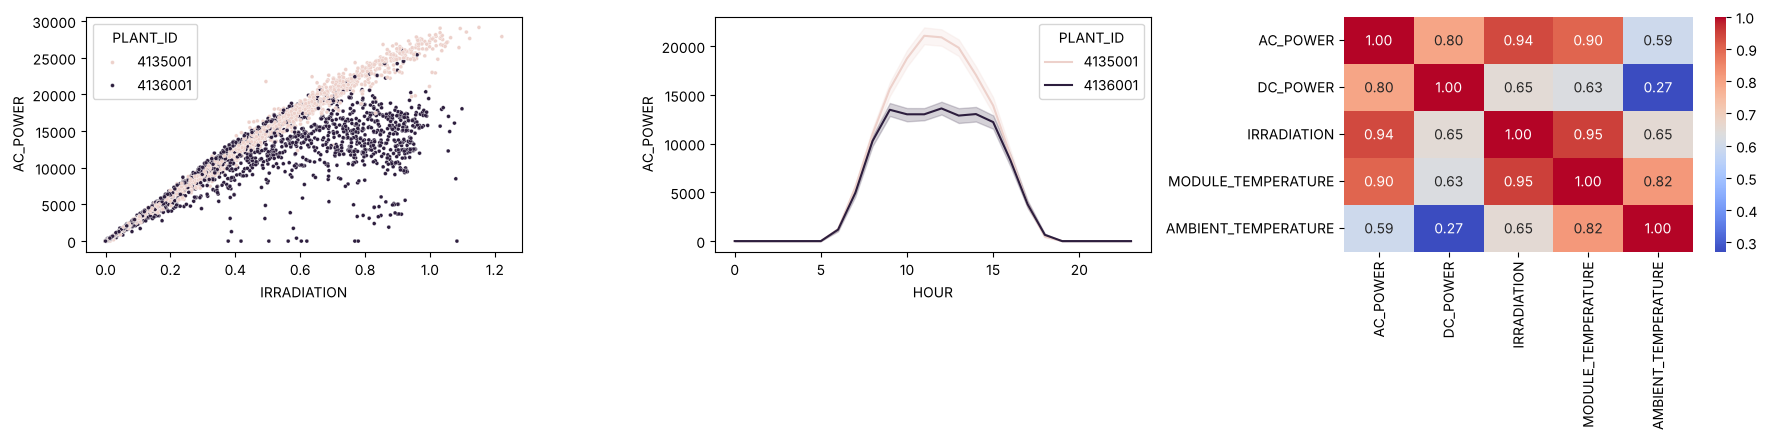

In [3]:
eda = df.copy()
eda['DATE_TIME'] = pd.to_datetime(eda['DATE_TIME'])
eda['HOUR'] = eda['DATE_TIME'].dt.hour

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.scatterplot(data=eda, x='IRRADIATION', y='AC_POWER', hue='PLANT_ID', s=8, ax=ax[0])
sns.lineplot(data=eda, x='HOUR', y='AC_POWER', hue='PLANT_ID', ax=ax[1])
sns.heatmap(eda[['AC_POWER', 'DC_POWER', 'IRRADIATION', 'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', ax=ax[2])
plt.tight_layout()
plt.show()

In [4]:
df['DATE_TIME'] = pd.to_datetime(df['DATE_TIME'])
df = df.drop_duplicates(['DATE_TIME', 'PLANT_ID']).sort_values(['DATE_TIME', 'PLANT_ID'])
df['PLANT'] = df['PLANT_ID'].map({4135001: 'Plant 1', 4136001: 'Plant 2'})

# only one row has no weather readings, so just drop it
df = df.dropna().reset_index(drop=True)

# night zeros are normal, so only physically impossible values get removed
bad = (df['IRRADIATION'] < 0) | (df['IRRADIATION'] > 1.5) | (df['AC_POWER'] < 0) | (df['MODULE_TEMPERATURE'] > 90)
print('impossible rows:', bad.sum())
df = df[~bad].reset_index(drop=True)

# zero output in good sun, per plant
sunny = df[df['IRRADIATION'] > 0.3]
print(sunny.groupby('PLANT')['AC_POWER'].apply(lambda s: (s == 0).sum()))

impossible rows: 0
PLANT
Plant 1    0
Plant 2    9
Name: AC_POWER, dtype: int64


In [5]:
t = df['DATE_TIME'].dt.hour + df['DATE_TIME'].dt.minute / 60
df['TOD_SIN'] = np.sin(2 * np.pi * t / 24)
df['TOD_COS'] = np.cos(2 * np.pi * t / 24)
df['DATE'] = df['DATE_TIME'].dt.date

weather = ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE']
with_time = weather + ['TOD_SIN', 'TOD_COS']
target = 'AC_POWER'
plants = ['Plant 1', 'Plant 2']

In [6]:
days = np.sort(df['DATE'].unique())
n = len(days)
df['SPLIT'] = 'test'
df.loc[df['DATE'].isin(days[:int(n * 0.70)]), 'SPLIT'] = 'train'
df.loc[df['DATE'].isin(days[int(n * 0.70):int(n * 0.85)]), 'SPLIT'] = 'validation'
print(df.groupby('SPLIT')['DATE'].agg(['min', 'max', 'nunique']))

def part(plant, split):
    return df[(df['PLANT'] == plant) & (df['SPLIT'] == split)]

                   min         max  nunique
SPLIT                                      
test        2020-06-12  2020-06-17        6
train       2020-05-15  2020-06-06       23
validation  2020-06-07  2020-06-11        5


In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def scores(y, p):
    rmse = np.sqrt(mean_squared_error(y, p))
    return {'MAE': mean_absolute_error(y, p), 'RMSE': rmse, 'R2': r2_score(y, p), 'NRMSE_%': 100 * rmse / y.mean()}

def make_rf(params):
    return RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1, **params)

In [8]:
# does time of day help once the weather is known? compare on validation days
grid = list(ParameterGrid({'max_depth': [None, 12], 'min_samples_leaf': [1, 3, 5]}))
features, best_params = {}, {}

for plant in plants:
    tr, va = part(plant, 'train'), part(plant, 'validation')
    best = {}
    for name, cols in [('weather only', weather), ('weather + time', with_time)]:
        for p in grid:
            rf = make_rf(p).fit(tr[cols], tr[target])
            rmse = np.sqrt(mean_squared_error(va[target], rf.predict(va[cols])))
            if name not in best or rmse < best[name][0]:
                best[name] = (rmse, p)
    use_time = best['weather + time'][0] < 0.95 * best['weather only'][0]
    pick = 'weather + time' if use_time else 'weather only'
    features[plant] = with_time if use_time else weather
    best_params[plant] = best[pick][1]
    print(plant, {k: round(v[0]) for k, v in best.items()}, '->', pick, best_params[plant])

Plant 1 {'weather only': 785, 'weather + time': 789} -> weather only {'max_depth': None, 'min_samples_leaf': 3}


Plant 2 {'weather only': 1980, 'weather + time': 1887} -> weather only {'max_depth': None, 'min_samples_leaf': 5}


In [9]:
rows = []
for plant in plants:
    cols = features[plant]
    tr, va = part(plant, 'train'), part(plant, 'validation')
    models = {
        'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
        'SVR': TransformedTargetRegressor(make_pipeline(StandardScaler(), SVR(C=10, epsilon=0.05)),
                                          transformer=StandardScaler()),
        'Random Forest': make_rf(best_params[plant]),
    }
    for name, m in models.items():
        pred = np.clip(m.fit(tr[cols], tr[target]).predict(va[cols]), 0, None)
        rows.append({'Plant': plant, 'Model': name, **scores(va[target], pred)})

val_scores = pd.DataFrame(rows)
val_scores.round(3)

,Plant,Model,MAE,RMSE,R2,NRMSE_%
0,Plant 1,Linear Regression,489.654,980.117,0.987,14.843
1,Plant 1,SVR,412.685,823.282,0.991,12.468
2,Plant 1,Random Forest,342.745,785.071,0.991,11.889
3,Plant 2,Linear Regression,1575.209,2575.985,0.820,53.388
4,Plant 2,SVR,779.086,1992.539,0.892,41.296
5,Plant 2,Random Forest,808.572,1979.821,0.894,41.032


In [10]:
MIN_PRED = 500   # kW, percentage deviation is only judged above this
K = 3.5
rf_train, rf_final, thr, center, spread = {}, {}, {}, {}, {}
rows = []

for plant in plants:
    cols = features[plant]
    tr, va, te = part(plant, 'train'), part(plant, 'validation'), part(plant, 'test')
    both = pd.concat([tr, va])

    rf_train[plant] = make_rf(best_params[plant]).fit(tr[cols], tr[target])
    rf_final[plant] = make_rf(best_params[plant]).fit(both[cols], both[target])

    # threshold from the validation errors of the train-only model (daytime rows)
    pv = np.clip(rf_train[plant].predict(va[cols]), 0, None)
    ok = pv >= MIN_PRED
    rel = (va[target].values[ok] - pv[ok]) / pv[ok]
    med = np.median(rel)
    mad = 1.4826 * np.median(np.abs(rel - med))
    center[plant], spread[plant] = med, mad
    thr[plant] = (med - K * mad, med + K * mad)

    pt = np.clip(rf_train[plant].predict(te[cols]), 0, None)
    rows.append({'Plant': plant, **scores(te[target], pt)})

print({p: (round(float(100 * a), 1), round(float(100 * b), 1)) for p, (a, b) in thr.items()})
test_scores = pd.DataFrame(rows)
test_scores.round(3)

{'Plant 1': (-20.5, 22.3), 'Plant 2': (-32.3, 46.9)}


,Plant,MAE,RMSE,R2,NRMSE_%
0,Plant 1,270.851,539.172,0.995,8.759
1,Plant 2,885.883,1918.223,0.882,42.675


In [11]:
parts = []
for plant in plants:
    te = part(plant, 'test').copy()
    te['PREDICTED'] = np.clip(rf_train[plant].predict(te[features[plant]]), 0, None)
    te['RESIDUAL'] = te[target] - te['PREDICTED']
    ok = te['PREDICTED'] >= MIN_PRED
    te['PCT_DEV'] = 100 * te['RESIDUAL'] / te['PREDICTED'].where(ok)
    lo, hi = thr[plant]
    te['IS_ANOMALY'] = ok & ((te['PCT_DEV'] < 100 * lo) | (te['PCT_DEV'] > 100 * hi))
    te['TYPE'] = np.select(
        [~te['IS_ANOMALY'], te[target] == 0, te['RESIDUAL'] < 0],
        ['', 'Zero reading (possible data gap)', 'Below expected'],
        default='Above expected')
    parts.append(te)

test_res = pd.concat(parts).sort_values(['DATE_TIME', 'PLANT'])
anomalies = test_res[test_res['IS_ANOMALY']]
print('flagged:', len(anomalies), 'of', len(test_res))
print(anomalies.groupby(['PLANT', 'TYPE']).size())
anomalies[['DATE_TIME', 'PLANT', 'AC_POWER', 'PREDICTED', 'PCT_DEV', 'IRRADIATION', 'MODULE_TEMPERATURE', 'TYPE']]

flagged: 23 of 1150
PLANT    TYPE                            
Plant 1  Above expected                       1
         Below expected                       1
Plant 2  Above expected                       6
         Below expected                      13
         Zero reading (possible data gap)     2
dtype: int64


,DATE_TIME,PLANT,AC_POWER,PREDICTED,PCT_DEV,IRRADIATION,MODULE_TEMPERATURE,TYPE
5361,2020-06-12 11:45:00,Plant 2,12837.900476,8642.931560,48.536413,0.367614,29.327403,Above expected
5365,2020-06-12 12:15:00,Plant 2,13020.363810,8422.782587,54.585063,0.382372,26.914875,Above expected
5367,2020-06-12 12:30:00,Plant 2,12793.040952,8435.595477,51.655458,0.382436,31.102586,Above expected
5371,2020-06-12 13:00:00,Plant 2,3078.351905,12256.024147,-74.882948,0.491243,39.878408,Below expected
5537,2020-06-13 09:45:00,Plant 2,5864.740000,15416.636999,-61.958370,0.607118,40.380066,Below expected
5543,2020-06-13 10:30:00,Plant 2,3506.090000,13866.712314,-74.715780,0.794066,47.455201,Below expected
5545,2020-06-13 10:45:00,Plant 2,0.000000,11914.148755,-100.000000,0.503415,45.337588,Zero reading (possible data gap)
5547,2020-06-13 11:00:00,Plant 2,7473.686667,13293.848966,-43.780867,0.739426,43.363691,Below expected
5569,2020-06-13 13:45:00,Plant 2,5923.228095,9068.798715,-34.685637,0.291030,39.942485,Below expected
5753,2020-06-14 12:45:00,Plant 2,15244.790952,9887.273704,54.185991,0.884950,52.801106,Above expected


In [12]:
TARIFF = 6.0
HOURS = 0.25    # each reading is 15 minutes

fin = test_res.copy()
fin['SHORT_KWH'] = (-fin['RESIDUAL']).clip(lower=0) * HOURS
fin['FLAGGED_SHORT_KWH'] = fin['SHORT_KWH'].where(fin['IS_ANOMALY'], 0)

summary = fin.groupby('PLANT').apply(lambda g: pd.Series({
    'expected_kwh': g['PREDICTED'].sum() * HOURS,
    'actual_kwh': g[target].sum() * HOURS,
    'net_kwh': g['RESIDUAL'].sum() * HOURS,
    'flagged_shortfall_kwh': g['FLAGGED_SHORT_KWH'].sum()}), include_groups=False)
summary['net_money'] = summary['net_kwh'] * TARIFF
summary['flagged_shortfall_money'] = summary['flagged_shortfall_kwh'] * TARIFF
summary.round(1)

,expected_kwh,actual_kwh,net_kwh,flagged_shortfall_kwh,net_money,flagged_shortfall_money
PLANT,,,,,,
Plant 1,861802.7,883301.4,21498.7,113.9,128992.1,683.6
Plant 2,623468.2,647268.8,23800.5,27589.9,142803.3,165539.2


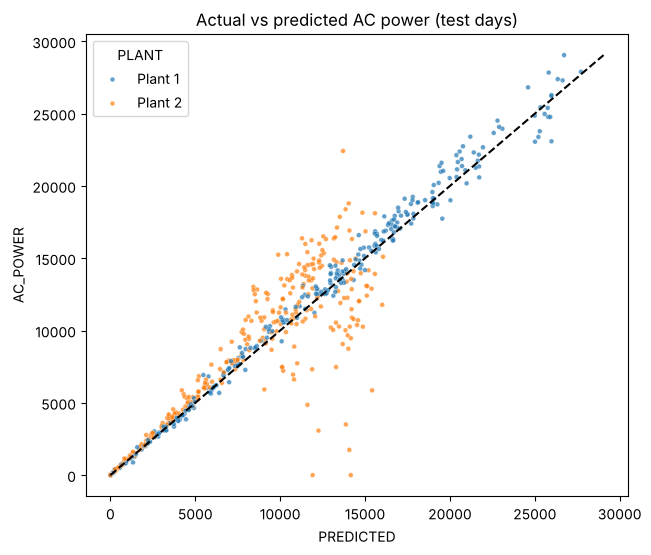

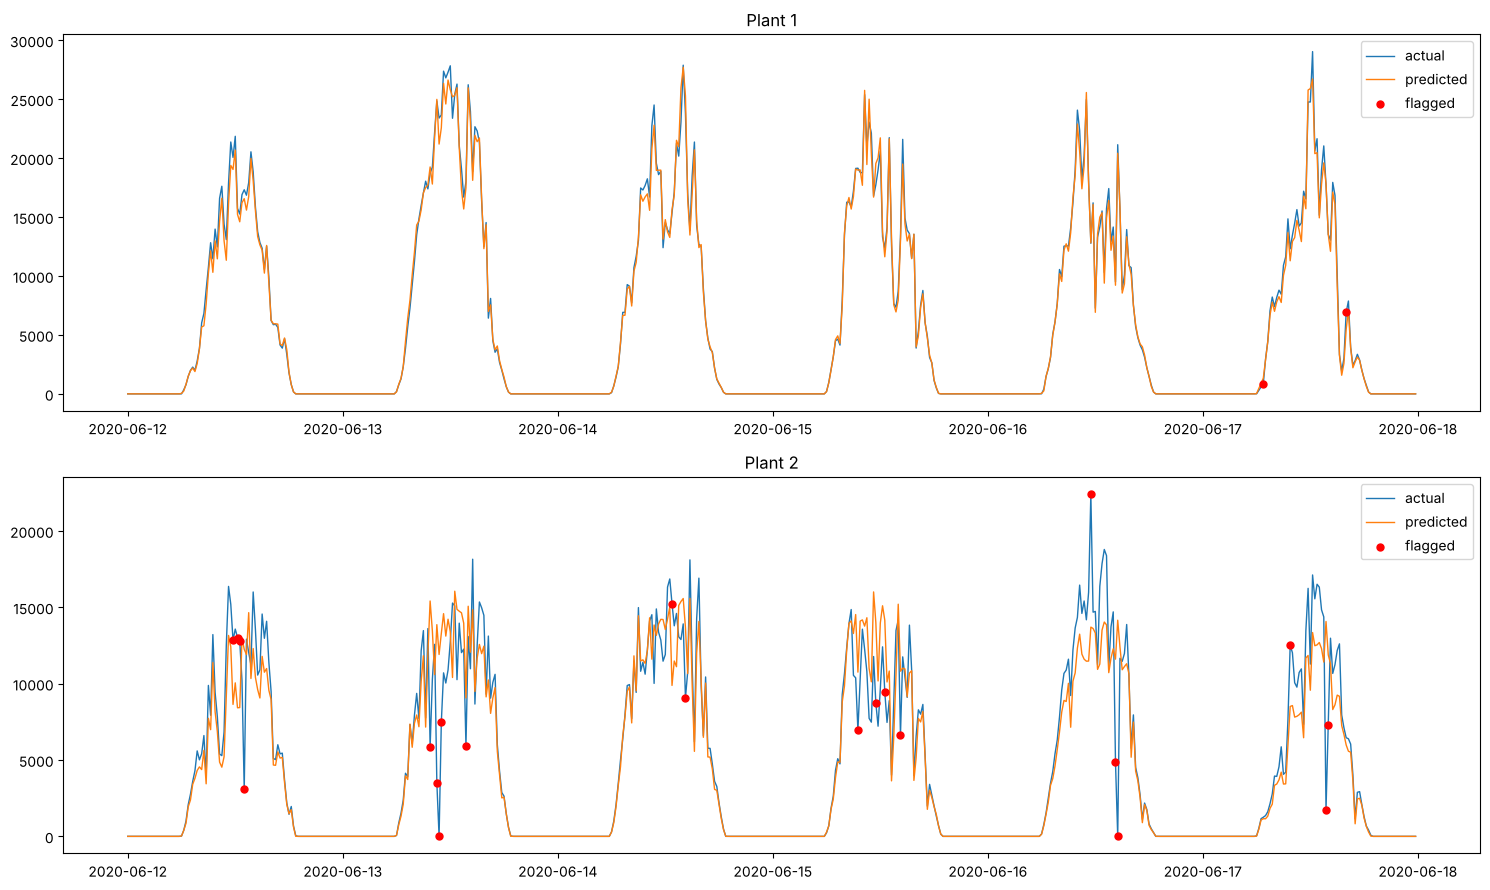

In [13]:
plt.figure(figsize=(7, 6))
sns.scatterplot(data=test_res, x='PREDICTED', y='AC_POWER', hue='PLANT', s=12, alpha=0.7)
top = test_res[['PREDICTED', 'AC_POWER']].max().max()
plt.plot([0, top], [0, top], 'k--')
plt.title('Actual vs predicted AC power (test days)')
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(15, 9))
for ax, plant in zip(axes, plants):
    d = test_res[test_res['PLANT'] == plant]
    ax.plot(d['DATE_TIME'], d['AC_POWER'], lw=1, label='actual')
    ax.plot(d['DATE_TIME'], d['PREDICTED'], lw=1, label='predicted')
    a = d[d['IS_ANOMALY']]
    ax.scatter(a['DATE_TIME'], a['AC_POWER'], color='red', s=25, zorder=3, label='flagged')
    ax.set_title(plant)
    ax.legend()
plt.tight_layout()
plt.show()

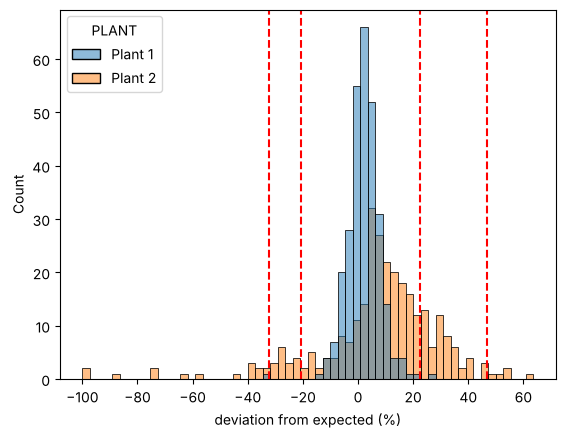

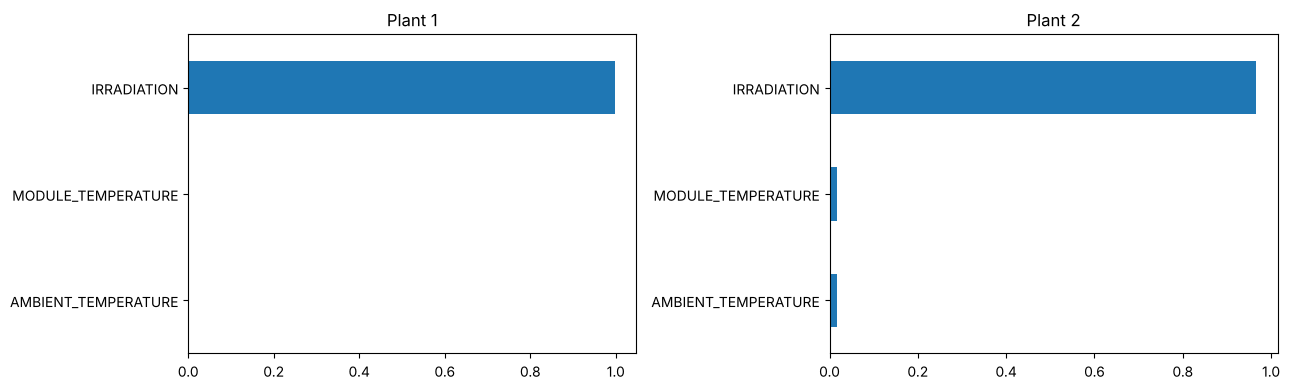

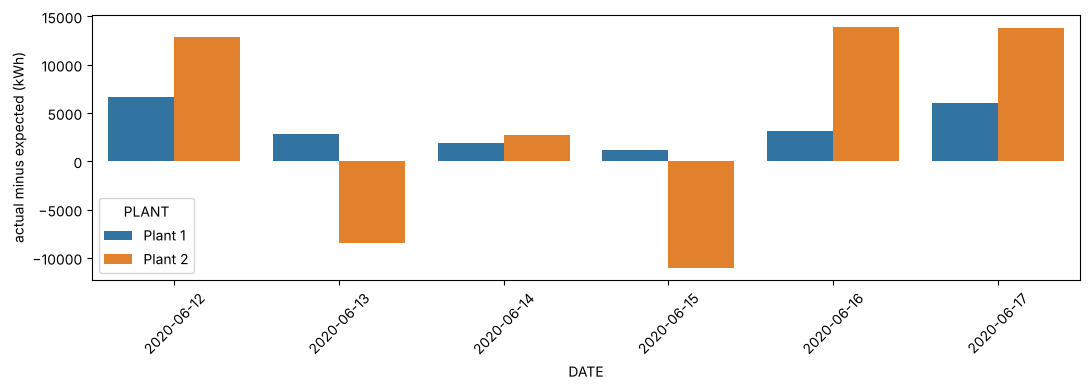

In [14]:
day = test_res[test_res['PREDICTED'] >= MIN_PRED]
sns.histplot(data=day, x='PCT_DEV', hue='PLANT', bins=60)
for lo, hi in thr.values():
    plt.axvline(100 * lo, color='red', ls='--')
    plt.axvline(100 * hi, color='red', ls='--')
plt.xlabel('deviation from expected (%)')
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, plant in zip(ax, plants):
    pd.Series(rf_final[plant].feature_importances_, index=features[plant]).sort_values().plot.barh(ax=a, title=plant)
plt.tight_layout()
plt.show()

daily = fin.assign(NET=fin['RESIDUAL'] * HOURS).groupby(['DATE', 'PLANT'])['NET'].sum().reset_index()
plt.figure(figsize=(11, 4))
sns.barplot(data=daily, x='DATE', y='NET', hue='PLANT')
plt.xticks(rotation=45)
plt.ylabel('actual minus expected (kWh)')
plt.tight_layout()
plt.show()

In [15]:
os.makedirs('artifacts/sample_outputs', exist_ok=True)

bundle = {
    'models': rf_final,
    'features': features,
    'center_pct': {p: float(100 * v) for p, v in center.items()},
    'spread_pct': {p: float(100 * v) for p, v in spread.items()},
    'thr_pct': {p: [float(100 * a), float(100 * b)] for p, (a, b) in thr.items()},
    'min_pred_kw': MIN_PRED,
    'k': K,
    'plant_flag': {4135001: 'Plant 1', 4136001: 'Plant 2'},
}
joblib.dump(bundle, 'artifacts/solar_rf_models.joblib', compress=3)

df.to_csv('artifacts/solar_clean.csv', index=False)
anomalies.to_csv('artifacts/solar_anomalies_test.csv', index=False)
test_res[['DATE_TIME', 'PLANT_ID', 'AC_POWER', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']] \
    .to_csv('artifacts/demo_upload.csv', index=False)

In [16]:
metrics = {
    'split': {s: [str(g['DATE'].min()), str(g['DATE'].max())] for s, g in df.groupby('SPLIT')},
    'features': features,
    'best_params': best_params,
    'validation_all_models': val_scores.round(4).to_dict(orient='records'),
    'test_random_forest': test_scores.round(4).to_dict(orient='records'),
    'threshold_pct': bundle['thr_pct'],
    'note': 'About one month of data (15 May to 17 Jun 2020), do not assume it holds in other seasons.',
}
json.dump(metrics, open('artifacts/model_metrics.json', 'w'), indent=2, default=str)

fi = {p: pd.Series(rf_final[p].feature_importances_, index=features[p]).round(5).to_dict() for p in plants}
json.dump(fi, open('artifacts/feature_importance.json', 'w'), indent=2)

wcols = ['AC_POWER'] + weather
df['HOUR'] = df['DATE_TIME'].dt.hour
weather_analysis = {
    'correlation_by_plant': {p: g[wcols].corr().round(4).to_dict() for p, g in df.groupby('PLANT')},
    'scatter_sample': df.sample(900, random_state=42)[['PLANT'] + weather + ['AC_POWER']].round(3).to_dict(orient='records'),
    'hourly_avg': df.groupby(['PLANT', 'HOUR'])['AC_POWER'].mean().round(1).reset_index().to_dict(orient='records'),
    'note': 'These are associations, not proof of cause.',
}
json.dump(weather_analysis, open('artifacts/weather_analysis.json', 'w'))

json.dump({'tariff': TARIFF, 'by_plant': summary.round(1).reset_index().to_dict(orient='records')},
          open('artifacts/sample_outputs/financial_sample.json', 'w'), indent=2)
json.dump(anomalies[['DATE_TIME', 'PLANT', 'AC_POWER', 'PREDICTED', 'PCT_DEV', 'TYPE']]
          .astype({'DATE_TIME': str}).round(2).head(10).to_dict(orient='records'),
          open('artifacts/sample_outputs/anomalies_sample.json', 'w'), indent=2)

import sys, sklearn
with open('artifacts/versions.txt', 'w') as f:
    for line in [f'python=={sys.version.split()[0]}', f'scikit-learn=={sklearn.__version__}', f'pandas=={pd.__version__}',
                 f'numpy=={np.__version__}', f'joblib=={joblib.__version__}']:
        print(line, file=f)
print(open('artifacts/versions.txt').read())

python==3.12.3
scikit-learn==1.9.1
pandas==3.0.6
numpy==2.5.4
joblib==1.6.0

